[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/exercises/solutions/ex_01_agriculture_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🌾 Solutions: Precision agriculture & crop intelligence
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Go beyond the four broadband indices of the theme notebook and use what only narrow bands can offer: the red edge, the cellulose absorption and full-spectrum segmentation — on irrigated fields of the Konya plain, Türkiye's main grain basket.

These exercises accompany the theme notebook [`01_agriculture_crop_intelligence.ipynb`](../../../notebooks/01_agriculture_crop_intelligence.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Turning an index threshold into an area estimate (hectares) and testing its sensitivity
- NDVI saturation and why red-edge indices help over dense canopies
- Computing the red-edge position from narrow bands
- Separating dry residue from bare soil with the Cellulose Absorption Index
- Unsupervised segmentation (PCA + k-means) of a full-spectrum window

**Data**
- `20250608_091605_90_4001` — Çumra, Konya plain, Türkiye (8 June 2025)
- `data/labels/…_worldcover2021_30m.tif` — ESA WorldCover 2021, aggregated to the Tanager 30 m grid

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20250608_091605_90_4001  (Konya, Türkiye)
File       : /home/course/notebooks/20250608_091605_90_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 673 rows × 776 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32636, 30 m pixels
No-data    : 30.4%   cloud flag: 1.2%   cirrus flag: 0.0%   usable: 68.4%


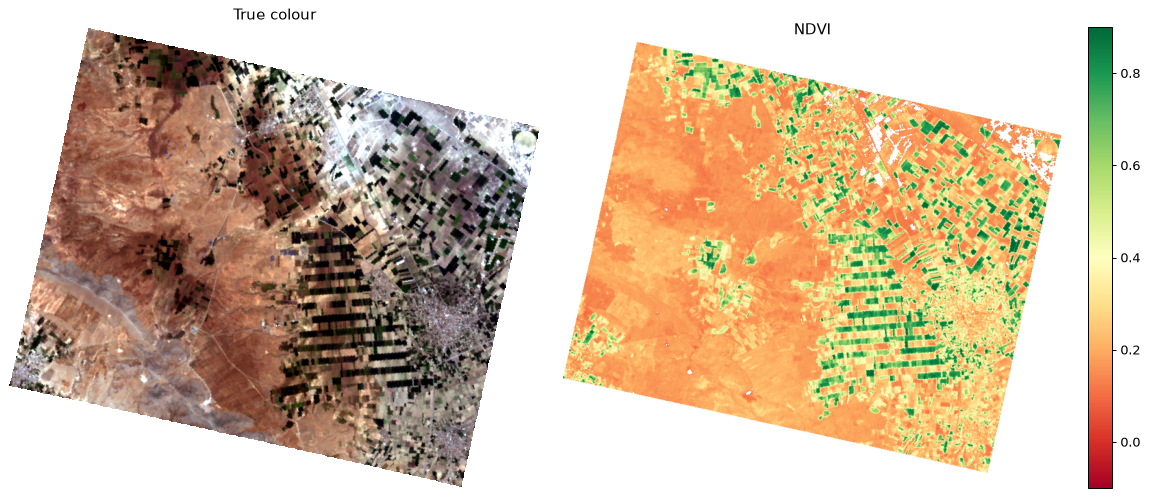

In [2]:
SCENE_ID = "20250608_091605_90_4001"   # Çumra, Konya plain, Türkiye (agriculture), 8 June 2025
scene = hu.get_scene(SCENE_ID)
print(scene.summary())

valid = scene.valid_mask()
R = {w: scene.read_band(w) for w in (570, 665, 705, 860, 1650)}   # the bands of notebook 01
NDVI = hu.nd(R[860], R[665])
NDRE = hu.nd(R[860], R[705])
PIXEL_HA = scene.res_x * scene.res_y / 10_000                     # 30 m × 30 m = 0.09 ha

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].imshow(scene.rgb()); axes[0].set_title("True colour"); axes[0].axis("off")
im = axes[1].imshow(NDVI, cmap="RdYlGn", vmin=-0.1, vmax=0.9); axes[1].set_title("NDVI"); axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

## Exercise 1 — How many hectares are green?  ⭐

In early June most rain-fed cereals on the Konya plain are already drying, so fields that are still green are
very likely **irrigated**.

1. Count the valid pixels with NDVI > 0.5 and convert the count to hectares and km².
2. What percentage of the valid scene is that?
3. Repeat with thresholds 0.4 and 0.6. How sensitive is the area estimate to the threshold?

### Solution

In [3]:
for t in (0.4, 0.5, 0.6):
    n = int((valid & (NDVI > t)).sum())
    print(f"NDVI > {t}: {n:7,d} px = {n * PIXEL_HA:8,.0f} ha = {n * PIXEL_HA / 100:6.1f} km²  "
          f"({n / valid.sum():.1%} of the valid scene)")

NDVI > 0.4:  66,458 px =    5,981 ha =   59.8 km²  (18.5% of the valid scene)
NDVI > 0.5:  50,060 px =    4,505 ha =   45.1 km²  (13.9% of the valid scene)
NDVI > 0.6:  37,244 px =    3,352 ha =   33.5 km²  (10.4% of the valid scene)


**Interpretation:** at NDVI > 0.5 the green area is roughly 4,500 ha (about 14% of the scene). Moving the
threshold by ±0.1 changes the estimate by several hundred to over a thousand hectares — a ±15–25% spread.
An area statistic is only as good as its threshold, so report the threshold and, ideally, justify it with
field data or a reference map (see Week 3, *Validation methods and accuracy assessment*).

## Exercise 2 — NDVI saturates — does NDRE?  ⭐⭐

NDVI tends to *saturate* over dense canopies: once the leaf area index is high, it stops increasing. NDRE uses
the red-edge band (705 nm), which is absorbed less strongly by chlorophyll and so keeps responding.

1. Make a 2-D histogram of NDVI (x) against NDRE (y) for all valid pixels.
2. For pixels with NDVI > 0.8, compare the spread (standard deviation) of NDVI and of NDRE.
3. In which NDVI range does NDRE keep separating pixels that NDVI lumps together?

### Solution

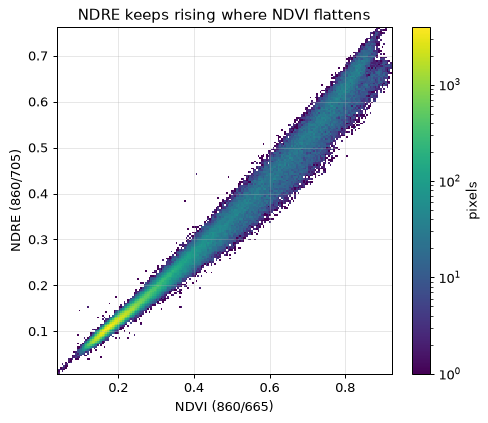

NDVI: dense pixels n=10,069  std=0.028  std / scene range = 0.038
NDRE: dense pixels n=10,069  std=0.039  std / scene range = 0.065


In [4]:
ok = valid & np.isfinite(NDVI) & np.isfinite(NDRE)
plt.figure(figsize=(6, 5))
plt.hist2d(NDVI[ok], NDRE[ok], bins=200, cmin=1, norm="log", cmap="viridis")
plt.xlabel("NDVI (860/665)"); plt.ylabel("NDRE (860/705)"); plt.colorbar(label="pixels")
plt.title("NDRE keeps rising where NDVI flattens"); plt.grid(alpha=0.3)
plt.show()

dense = ok & (NDVI > 0.8)
for name, idx in (("NDVI", NDVI), ("NDRE", NDRE)):
    rng = np.nanpercentile(idx[ok], 99) - np.nanpercentile(idx[ok], 1)
    print(f"{name}: dense pixels n={dense.sum():,}  std={np.nanstd(idx[dense]):.3f}  "
          f"std / scene range = {np.nanstd(idx[dense]) / rng:.3f}")

**Interpretation:** the cloud of points bends. Above NDVI ≈ 0.7 it is compressed horizontally (NDVI is
saturating) but still spread vertically — NDRE separates canopies with different chlorophyll content that NDVI
reports as "equally green". That is why red-edge indices are preferred for nitrogen and chlorophyll
monitoring of dense crops (Gitelson & Merzlyak, 1994). Over bare soil and sparse vegetation, NDVI has the
larger dynamic range.

## Exercise 3 — Red-edge position (REP) map  ⭐⭐

The **red-edge position** is the wavelength of the steepest slope between the red absorption and the NIR
plateau. It shifts to longer wavelengths as chlorophyll increases. With narrow bands you can estimate it with
the four-point linear interpolation of Guyot & Baret (1988):

$$R_{re} = \frac{R_{670} + R_{780}}{2}, \qquad
\mathrm{REP} = 700 + 40\,\frac{R_{re} - R_{700}}{R_{740} - R_{700}} \;\; [\mathrm{nm}]$$

1. Compute REP for vegetated pixels (NDVI > 0.5) and map it.
2. Plot its histogram and report the 5th, 50th and 95th percentiles.
3. Why can't you compute this with Sentinel-2 as precisely? (Look at `hu.SENTINEL2_BANDS`.)

### Solution

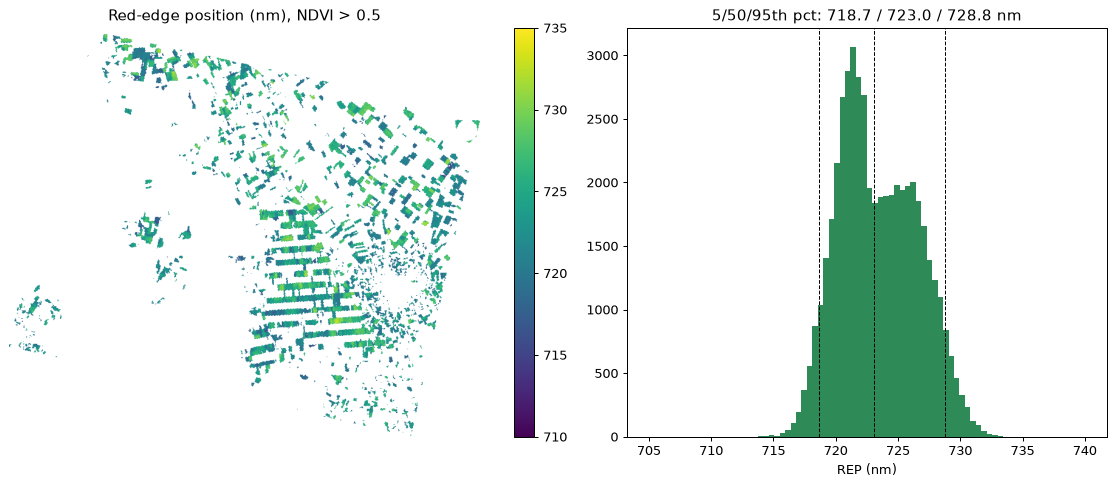

Sentinel-2 red-edge bands: {'B04': (664.6, 31), 'B05': (704.1, 15), 'B06': (740.5, 15), 'B07': (782.8, 20)}


In [5]:
R670, R700, R740, R780 = (scene.read_band(w) for w in (670, 700, 740, 780))
R_re = (R670 + R780) / 2
REP = 700 + 40 * (R_re - R700) / (R740 - R700)
veg = valid & (NDVI > 0.5)
REP_veg = np.where(veg, REP, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
im = axes[0].imshow(REP_veg, cmap="viridis", vmin=710, vmax=735)
axes[0].set_title("Red-edge position (nm), NDVI > 0.5"); axes[0].axis("off")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].hist(REP[veg], bins=80, range=(705, 740), color="seagreen")
p5, p50, p95 = np.nanpercentile(REP[veg], [5, 50, 95])
for p in (p5, p50, p95):
    axes[1].axvline(p, color="k", ls="--", lw=0.8)
axes[1].set_xlabel("REP (nm)"); axes[1].set_title(f"5/50/95th pct: {p5:.1f} / {p50:.1f} / {p95:.1f} nm")
plt.tight_layout(); plt.show()

print("Sentinel-2 red-edge bands:", {k: hu.SENTINEL2_BANDS[k] for k in ("B04", "B05", "B06", "B07")})

**Interpretation:** the REP of the green fields lies between about 718 and 729 nm, which is typical of
healthy crops. Fields with an REP at the low end have less chlorophyll (they are younger, senescing or
nitrogen-limited), and fields at the high end have dense, chlorophyll-rich canopies. Within one field the REP
is fairly uniform, while it differs clearly *between* fields, as you'd expect from different crops and sowing
dates.

Sentinel-2 samples the red edge with only three 15–20 nm wide bands (B5–B7) centred at 704, 740 and 783 nm,
so the REP has to be interpolated from much coarser information. Tanager samples the edge every ~5 nm.

## Exercise 4 — Dry residue vs bare soil: the Cellulose Absorption Index  ⭐⭐

Senescent steppe grass, stubble and bare soil all have **low NDVI** — NDVI cannot tell them apart. Dry plant
material, however, has a cellulose/lignin absorption near 2100 nm that soils lack. The **Cellulose
Absorption Index** (Nagler et al., 2000) measures it:

$$\mathrm{CAI} = 0.5\,(R_{2031} + R_{2211}) - R_{2101}$$

1. Compute CAI for the scene.
2. Compare CAI and NDVI for three groups: green crops (NDVI > 0.6), bare soil (NDVI < 0.12) and dry steppe
   (WorldCover class 30 = grassland, 0.12 < NDVI < 0.25). Use box plots.
3. Which index separates bare soil from dry vegetation better?

### Solution

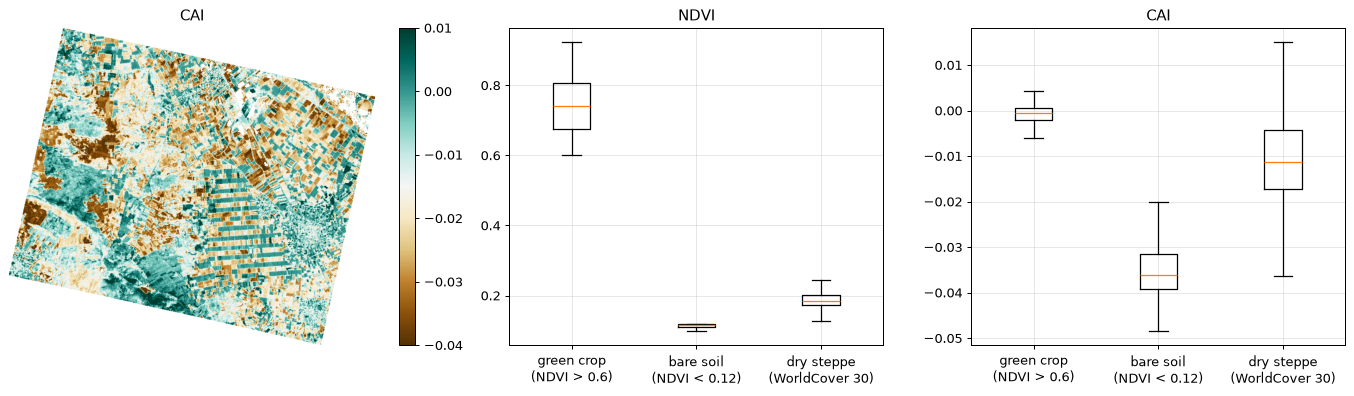

green crop (NDVI > 0.6)          n= 37,244  NDVI median 0.741   CAI median -0.0006
bare soil (NDVI < 0.12)          n=  2,597  NDVI median 0.115   CAI median -0.0361
dry steppe (WorldCover 30)       n= 58,576  NDVI median 0.185   CAI median -0.0112


In [6]:
R2031, R2101, R2211 = (scene.read_band(w) for w in (2031, 2101, 2211))
CAI = 0.5 * (R2031 + R2211) - R2101
lab, purity = hu.load_labels(SCENE_ID)

groups = {"green crop\n(NDVI > 0.6)": valid & (NDVI > 0.6),
          "bare soil\n(NDVI < 0.12)": valid & (NDVI < 0.12),
          "dry steppe\n(WorldCover 30)": valid & (lab == 30) & (NDVI > 0.12) & (NDVI < 0.25)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
im = axes[0].imshow(np.where(valid, CAI, np.nan), cmap="BrBG", vmin=-0.04, vmax=0.01)
axes[0].set_title("CAI"); axes[0].axis("off"); plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].boxplot([NDVI[m] for m in groups.values()], showfliers=False)
axes[1].set_xticks(range(1, 4), list(groups))
axes[1].set_title("NDVI"); axes[1].grid(alpha=0.3)
axes[2].boxplot([CAI[m] for m in groups.values()], showfliers=False)
axes[2].set_xticks(range(1, 4), list(groups))
axes[2].set_title("CAI"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

for name, m in groups.items():
    print(f"{name.replace(chr(10), ' '):32s} n={m.sum():7,d}  NDVI median {np.nanmedian(NDVI[m]):.3f}   CAI median {np.nanmedian(CAI[m]):+.4f}")

**Interpretation:** by construction, bare soil and dry steppe barely differ in NDVI, but their CAI values
separate clearly: bare soil is strongly negative, around −0.036 (the soil spectrum *rises* from 2100 to
2200 nm), while dry steppe sits near −0.01 to 0 (cellulose absorption at 2100 nm pulls R₂₁₀₁ down). Green crops
are close to zero because leaf water masks the cellulose feature.

This is a classic hyperspectral advantage: the 2100 nm feature is ~50 nm wide and falls between Sentinel-2's
B11 and B12. Applications include crop-residue cover (conservation tillage), fire-fuel load and rangeland
condition. Note that the *absolute* CAI values here are more negative than in the original paper, because the
calcareous soils of the Konya plain have strong SWIR features of their own. Always calibrate locally.

## Exercise 5 — Segment the strip fields with k-means  ⭐⭐⭐

The striped irrigated fields south-east of the scene centre are a nice test for **unsupervised segmentation**.

1. Read the full-band cube for the window `(300, 500, 400, 600)` (rows 300–500, cols 400–600).
2. Reduce it to 10 principal components (PCA) and cluster the pixels with k-means (k = 6).
3. Show the true-colour window, NDVI and the cluster map side by side, and plot the mean spectrum of each
   cluster.
4. Give each cluster a name based on its mean spectrum and report its area in hectares.

### Solution

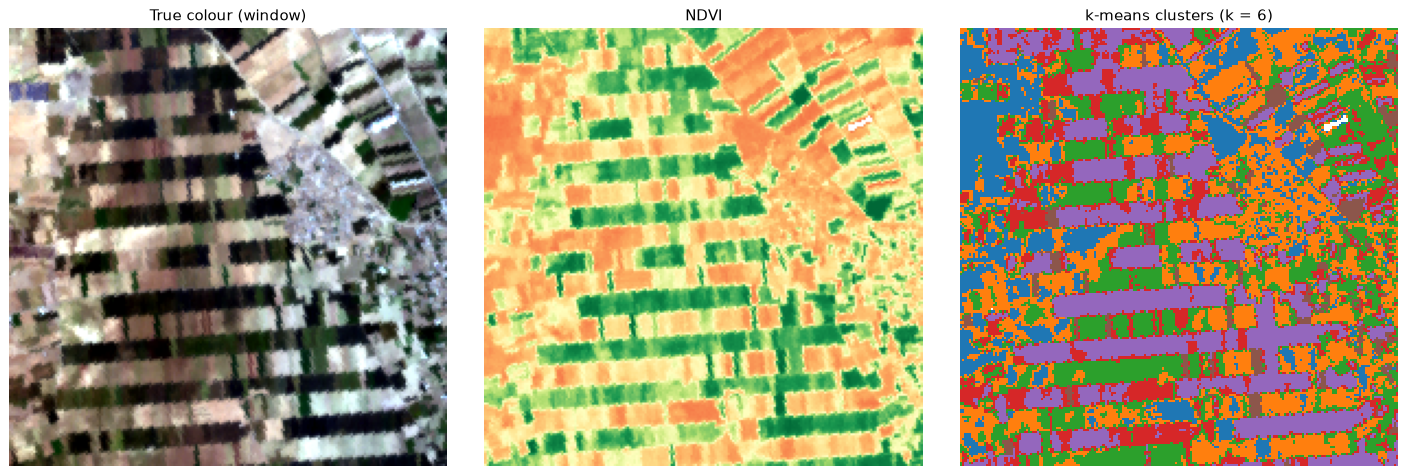

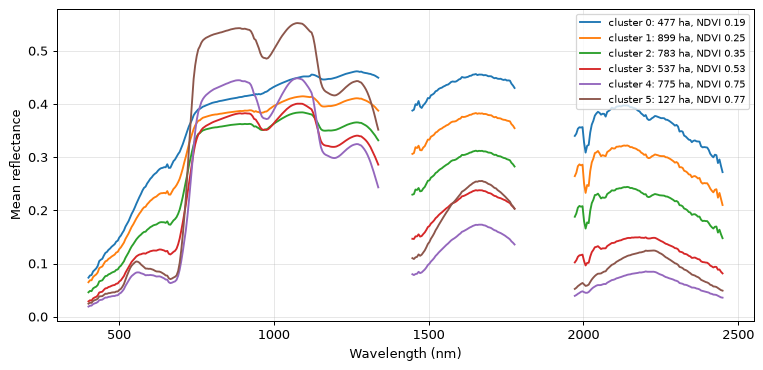

In [7]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

WINDOW = (300, 500, 400, 600)
cube, wl = scene.read_cube(WINDOW)
X, ok = hu.cube_to_pixels(cube)
Z = PCA(n_components=10, random_state=0).fit_transform(X)
km = KMeans(n_clusters=6, n_init=10, random_state=0).fit(Z)
# order clusters by mean NDVI so the colours are reproducible
ndvi_px = hu.nd(X[:, hu.band_index(wl, 860)], X[:, hu.band_index(wl, 665)])
order = np.argsort([ndvi_px[km.labels_ == k].mean() for k in range(6)])
labels = np.argsort(order)[km.labels_]
cluster_map = hu.pixels_to_image(labels.astype(float), ok)

r0, r1, c0, c1 = WINDOW
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
axes[0].imshow(hu.rgb_from_cube(cube, wl)); axes[0].set_title("True colour (window)")
axes[1].imshow(NDVI[r0:r1, c0:c1], cmap="RdYlGn", vmin=-0.1, vmax=0.9); axes[1].set_title("NDVI")
axes[2].imshow(cluster_map, cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); axes[2].set_title("k-means clusters (k = 6)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
cmap = plt.get_cmap("tab10")
for k in range(6):
    m = labels == k
    hu.plot_spectrum(ax, wl, X[m].mean(axis=0), color=cmap(k),
                     label=f"cluster {k}: {m.sum() * PIXEL_HA:,.0f} ha, NDVI {ndvi_px[m].mean():.2f}")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Mean reflectance"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

**Interpretation:** k-means finds the structure without any labels. The clusters are ordered by NDVI
(0 = least green):
- **Low-NDVI clusters:** bright bare or harvested fields, darker moist or ploughed soils, and mixed
  field-edge pixels. They differ mostly in brightness and in their SWIR shape.
- **High-NDVI clusters:** green irrigated crops, often split by canopy density or crop type. You can see it
  in the NIR plateau height and in the depth of the SWIR water features.

k-means clusters are *spectral* groups, not land-use classes: one crop can be split in two, and two crops can
share a cluster. Turning clusters into classes needs labels, which is the step from Week 2 *Classification
approaches* (supervised learning).

## Exercise 6 — Reflection — stress, or just a different crop?  ⭐

The theme notebook says hyperspectral data can detect crop stress "weeks before visible damage". Using
your REP and NDRE results, answer in a short markdown cell:

1. Two neighbouring green fields have the same NDVI but one has a clearly lower REP. List at least three
   explanations other than "stress".
2. What additional data would you need to turn the REP map into a **stress alert** that a farmer or an
   agricultural ministry could act on?

### Solution

**Model answer**
1. A lower REP with the same NDVI can mean a **different crop** (e.g. maize vs sugar beet have different leaf
   chlorophyll and canopy architecture), a **different growth stage** (a later-sown field, or one entering
   senescence), a different **irrigation timing** (recently irrigated fields have darker soil between the
   rows), a different **soil background** visible through the canopy, or different **leaf angles** and
   illumination geometry. Nutrient or water stress is only one of several causes.
2. A stress alert needs a **baseline per field and per crop**: field boundaries and crop-type maps (cadastre or
   farmer declarations), a **time series** so that a drop can be compared with the field's own trajectory
   and with fields of the same crop, and **ground truth** (agronomist visits, leaf chlorophyll or nitrogen
   measurements) to calibrate thresholds. Weather and irrigation records help to explain the anomalies.
   The product then flags *deviations from the expected*, not low absolute values.

## Key takeaways

- An area statistic is only as good as its threshold — test the sensitivity and report it.
- Red-edge indices and the REP keep responding where NDVI saturates.
- SWIR features (such as CAI at 2100 nm) separate materials that are identical in NDVI.
- Unsupervised clusters show spectral structure; labels are needed to turn them into classes.
- A stress product needs field-level baselines, time series and ground truth.

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC  
> 📖 Labels: ESA WorldCover 2021 v200 — CC-BY 4.0